# Scenario and Impact Analysis - 2026-11-07 - stevin5550

In [5]:
# Import libraries and load the credit card dataset
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "stevin5550"
data_path = next(
    (p for p in (Path.cwd() / "Methods&Modeling" / "Credit_card_data.csv",
                 Path.cwd() / "Credit_card_data.csv") if p.exists()),
    None,
)
if data_path is None:
    raise FileNotFoundError("Could not find Credit_card_data.csv")
credit = pd.read_csv(data_path)

display(Markdown("### Step 1: Load the Credit Card Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
print(f"Dataset shape: {credit.shape}")
print(f"Columns: {credit.columns.tolist()}")

### Step 1: Load the Credit Card Dataset

Date: 2026-11-07

Student ID: stevin5550

Dataset shape: (1319, 12)
Columns: ['card', 'reports', 'age', 'income', 'share', 'expenditure', 'owner', 'selfemp', 'dependents', 'months', 'majorcards', 'active']


In [6]:
display(Markdown("### Step 2: Train the Optimized Expenditure Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Recreate the tuned random forest regression workflow from 3.2MethodsLab.
X = credit.drop(columns=["expenditure", "card"])
y = credit["expenditure"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore"),
    ), categorical_features),
])
regression_grid = GridSearchCV(
    make_pipeline(
        preprocessor,
        RandomForestRegressor(criterion="squared_error", random_state=42),
    ),
    {
        "randomforestregressor__n_estimators": [100, 200],
        "randomforestregressor__max_depth": [None, 10, 20],
        "randomforestregressor__min_samples_leaf": [1, 2, 4],
    },
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
regression_grid.fit(X_train, y_train)
optimized_regressor = regression_grid.best_estimator_
baseline_predictions = optimized_regressor.predict(X_test)

print(f"Best parameters: {regression_grid.best_params_}")
print(f"Test RMSE: {mean_squared_error(y_test, baseline_predictions) ** 0.5:.2f}")
print(f"Test MAE: {mean_absolute_error(y_test, baseline_predictions):.2f}")
print(f"Test R-squared: {r2_score(y_test, baseline_predictions):.3f}")

### Step 2: Train the Optimized Expenditure Model

Date: 2026-11-07

Student ID: stevin5550

Best parameters: {'randomforestregressor__max_depth': 10, 'randomforestregressor__min_samples_leaf': 1, 'randomforestregressor__n_estimators': 200}
Test RMSE: 84.72
Test MAE: 20.95
Test R-squared: 0.920


## Step 3: Scenario Development

The model predicts credit card expenditure from the other fields in the dataset. The baseline uses the held-out customers as recorded. The scenarios change their reported annual income and credit-use share while keeping all other characteristics unchanged:

- **Higher income:** income increases by 10%, representing improved household earnings.
- **Higher credit use:** share increases by 20%, representing greater reliance on credit for purchases.
- **Financial pressure:** income decreases by 10% while share increases by 20%, representing reduced earnings and increased credit use.

These are hypothetical input changes to test model response, not causal estimates. Percentage changes are illustrative; modified values may extend beyond the observed training range.

In [7]:
display(Markdown("### Step 4: Simulate the Scenarios"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

scenario_inputs = {
    "Baseline": X_test.copy(),
    "Higher income (+10%)": X_test.copy(),
    "Higher credit use (+20%)": X_test.copy(),
    "Financial pressure": X_test.copy(),
}
scenario_inputs["Higher income (+10%)"]["income"] *= 1.10
scenario_inputs["Higher credit use (+20%)"]["share"] = (
    scenario_inputs["Higher credit use (+20%)"]["share"] * 1.20
).clip(upper=credit["share"].max())
scenario_inputs["Financial pressure"]["income"] *= 0.90
scenario_inputs["Financial pressure"]["share"] = (
    scenario_inputs["Financial pressure"]["share"] * 1.20
).clip(upper=credit["share"].max())

scenario_predictions = {
    name: optimized_regressor.predict(features)
    for name, features in scenario_inputs.items()
}
baseline_mean = scenario_predictions["Baseline"].mean()
scenario_results = pd.DataFrame([
    {
        "Scenario": name,
        "Mean predicted expenditure": predictions.mean(),
        "Difference from baseline": predictions.mean() - baseline_mean,
        "Percent change from baseline": (
            (predictions.mean() / baseline_mean - 1) * 100
        ),
    }
    for name, predictions in scenario_predictions.items()
])
display(scenario_results.round(2))

### Step 4: Simulate the Scenarios

Date: 2026-11-07

Student ID: stevin5550

,Scenario,Mean predicted expenditure,Difference from baseline,Percent change from baseline
0,Baseline,179.16,0.00,0.00
1,Higher income (+10%),193.03,13.87,7.74
2,Higher credit use (+20%),215.85,36.68,20.48
3,Financial pressure,200.58,21.42,11.96


### Step 5: Compare Scenario Predictions

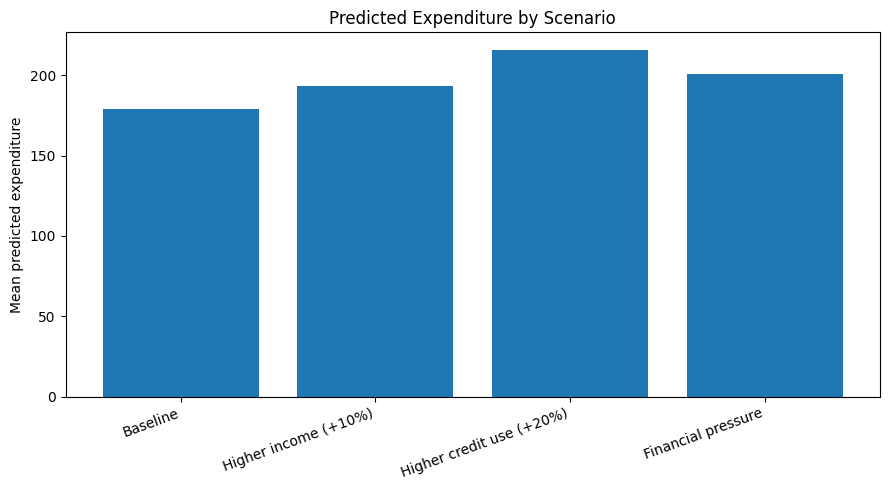

In [8]:
display(Markdown("### Step 5: Compare Scenario Predictions"))

plt.figure(figsize=(9, 5))
plt.bar(
    scenario_results["Scenario"],
    scenario_results["Mean predicted expenditure"],
)
plt.ylabel("Mean predicted expenditure")
plt.title("Predicted Expenditure by Scenario")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Step 6: Sensitivity Analysis for Income and Credit Use

Credit-use share multiplier,0.8,0.9,1.0,1.1,1.2
Income multiplier,,,,,
0.8,122.10,139.59,153.44,171.59,186.51
0.9,132.51,151.02,165.86,185.15,200.58
1.0,143.99,163.70,179.16,199.95,215.85
1.1,154.98,175.35,193.03,214.91,231.40
1.2,166.23,187.32,205.60,228.85,246.53


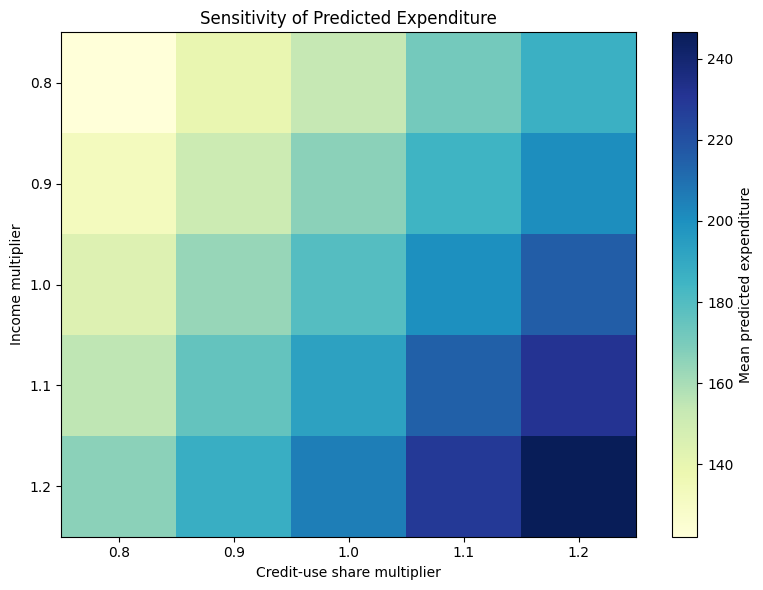

In [9]:
display(Markdown("### Step 6: Sensitivity Analysis for Income and Credit Use"))

income_multipliers = [0.8, 0.9, 1.0, 1.1, 1.2]
share_multipliers = [0.8, 0.9, 1.0, 1.1, 1.2]
sensitivity = pd.DataFrame(
    index=income_multipliers,
    columns=share_multipliers,
    dtype=float,
)
for income_change in income_multipliers:
    for share_change in share_multipliers:
        changed = X_test.copy()
        changed["income"] *= income_change
        changed["share"] = (changed["share"] * share_change).clip(
            upper=credit["share"].max()
        )
        sensitivity.loc[income_change, share_change] = (
            optimized_regressor.predict(changed).mean()
        )

sensitivity.index.name = "Income multiplier"
sensitivity.columns.name = "Credit-use share multiplier"
display(sensitivity.round(2))

plt.figure(figsize=(8, 6))
plt.imshow(sensitivity.values, cmap="YlGnBu", aspect="auto")
plt.colorbar(label="Mean predicted expenditure")
plt.xticks(range(len(share_multipliers)), share_multipliers)
plt.yticks(range(len(income_multipliers)), income_multipliers)
plt.xlabel("Credit-use share multiplier")
plt.ylabel("Income multiplier")
plt.title("Sensitivity of Predicted Expenditure")
plt.tight_layout()
plt.show()

## Step 7: Sensitivity and Impact Interpretation

On the held-out sample, the predicted average expenditure was 179.16 at baseline, 193.03 with income increased by 10%, 215.85 with credit-use share increased by 20%, and 200.58 under financial pressure. The sensitivity table increased steadily as either income or credit-use share rose; predicted averages ranged from 122.10 to 246.53 across the tested combinations. In practice, these results illustrate how the trained model responds to changes in customer profiles, but they are not causal financial forecasts or decisions about individuals.